# Task 5: Sales Prediction Using Python
**Objective:** Predict product sales from advertising spend on TV, Radio and Newspaper.

**Tech stack:** Python, pandas, scikit-learn, matplotlib, seaborn

**Dataset:** `Advertising.csv` (200 rows; TV, Radio, Newspaper spend and Sales). Keep the CSV in the same folder as this notebook.

## 1. Import Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

sns.set_theme(style='whitegrid')

## 2. Load the Dataset

In [2]:
df = pd.read_csv('Advertising.csv')
# Some versions of the file have an extra index column; drop it if present
df = df.drop(columns=[col for col in df.columns if col.startswith('Unnamed')])
df.head()

,TV,Radio,Newspaper,Sales
0,230.1,37.8,69.2,22.1
1,44.5,39.3,45.1,10.4
2,17.2,45.9,69.3,9.3
3,151.5,41.3,58.5,18.5
4,180.8,10.8,58.4,12.9


## 3. Exploratory Data Analysis (EDA)

In [3]:
print('Shape:', df.shape)
print('\nData types:')
print(df.dtypes)
print('\nNull values per column:')
print(df.isnull().sum())
print('\nDuplicate rows:', df.duplicated().sum())

Shape: (200, 4)

Data types:
TV           float64
Radio        float64
Newspaper    float64
Sales        float64
dtype: object

Null values per column:
TV           0
Radio        0
Newspaper    0
Sales        0
dtype: int64

Duplicate rows: 0


In [4]:
df.describe()

,TV,Radio,Newspaper,Sales
count,200.000000,200.000000,200.000000,200.000000
mean,147.042500,23.264000,30.554000,14.022500
std,85.854236,14.846809,21.778621,5.217457
min,0.700000,0.000000,0.300000,1.600000
25%,74.375000,9.975000,12.750000,10.375000
50%,149.750000,22.900000,25.750000,12.900000
75%,218.825000,36.525000,45.100000,17.400000
max,296.400000,49.600000,114.000000,27.000000


**Observations:** The dataset has 200 rows and 4 numeric columns with no missing values. TV has the largest spend range, while Radio and Newspaper have smaller budgets.

### 3.1 Pairplot of all features

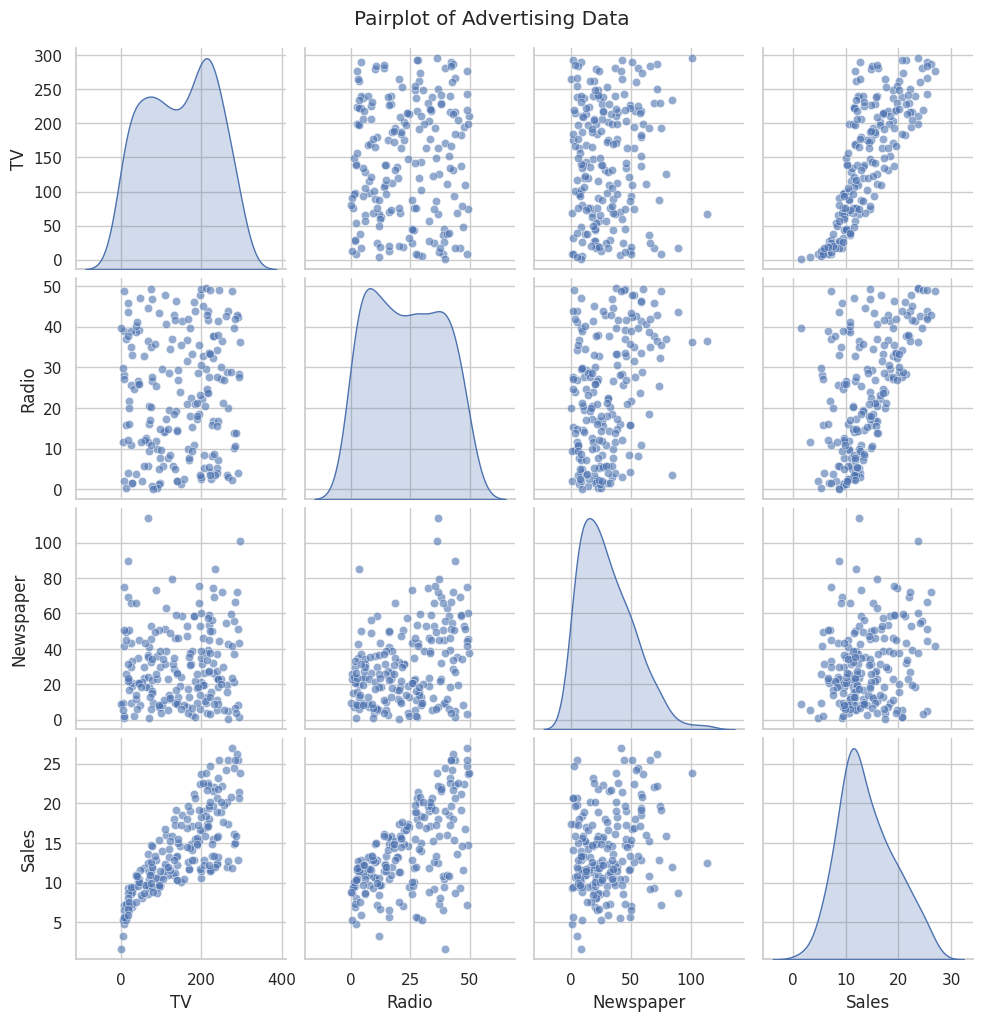

In [5]:
sns.pairplot(df, diag_kind='kde', plot_kws={'alpha': 0.6})
plt.suptitle('Pairplot of Advertising Data', y=1.02)
plt.show()

**Observation:** TV vs Sales shows a clear strong upward trend. Radio vs Sales shows a weaker positive trend. Newspaper vs Sales looks like a scattered cloud with almost no pattern.

### 3.2 Individual scatter plots: Sales vs each channel

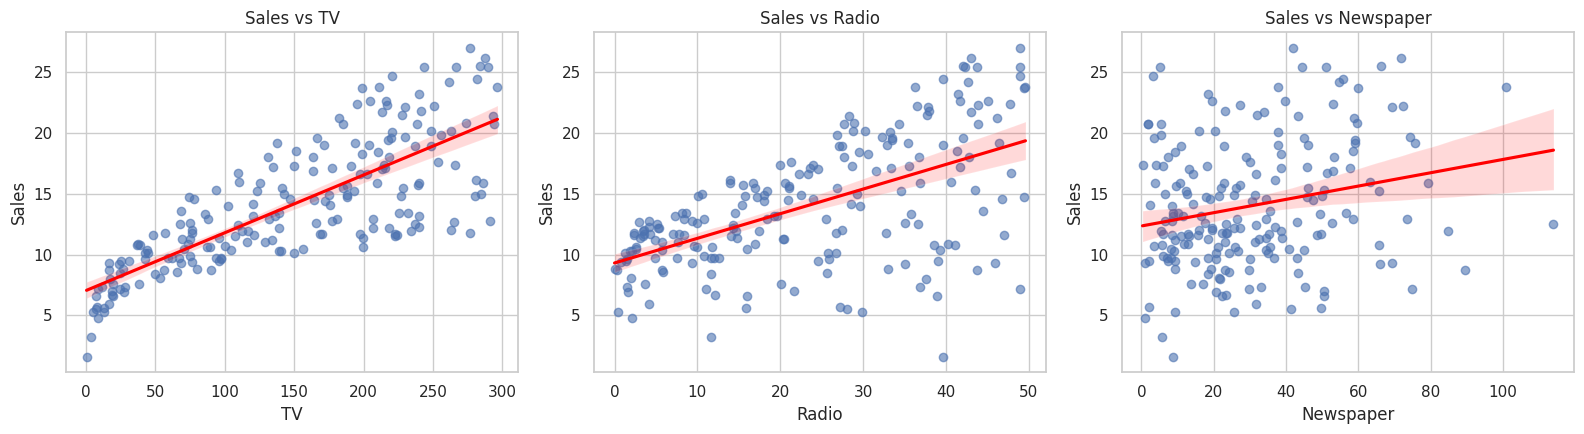

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, col in zip(axes, ['TV', 'Radio', 'Newspaper']):
    sns.regplot(data=df, x=col, y='Sales', ax=ax,
                scatter_kws={'alpha': 0.6}, line_kws={'color': 'red'})
    ax.set_title(f'Sales vs {col}')
plt.tight_layout()
plt.show()

**Observation:** The red trend line is steepest and tightest for TV. Radio has a clear but noisier slope. Newspaper's line is almost flat, so newspaper spend barely relates to sales.

### 3.3 Correlation matrix heatmap

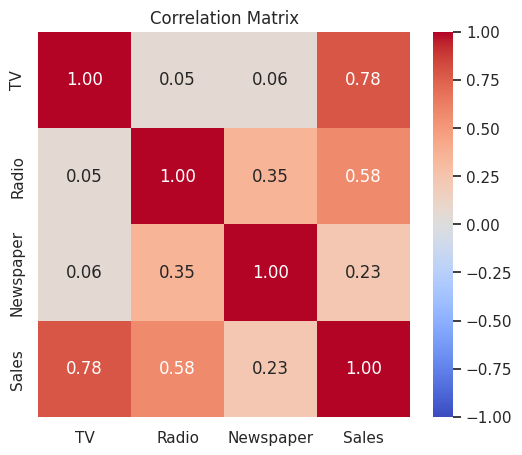

TV           0.782
Radio        0.576
Newspaper    0.228
Name: Sales, dtype: float64


In [7]:
plt.figure(figsize=(6, 5))
sns.heatmap(df.corr(), annot=True, cmap='coolwarm', fmt='.2f', vmin=-1, vmax=1)
plt.title('Correlation Matrix')
plt.show()
print(df.corr()['Sales'].drop('Sales').sort_values(ascending=False).round(3))

**Observation:** TV has the highest correlation with Sales, followed by Radio. Newspaper has a low correlation with Sales. Note that Newspaper and Radio are slightly correlated with each other, which can make Newspaper look more useful than it really is.

## 4. Train/Test Split (80/20)

In [8]:
X = df[['TV', 'Radio', 'Newspaper']]
y = df['Sales']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print('Train size:', X_train.shape[0], '| Test size:', X_test.shape[0])

Train size: 160 | Test size: 40


## 5. Train Models
1. **Linear Regression** (baseline)
2. **Polynomial Regression** (degree 2, with scaling)
3. **Random Forest Regressor**

In [9]:
models = {
    'Linear Regression': LinearRegression(),
    'Polynomial Regression (deg 2)': make_pipeline(
        PolynomialFeatures(degree=2, include_bias=False), StandardScaler(), LinearRegression()),
    'Random Forest': RandomForestRegressor(n_estimators=200, random_state=42),
}

rows, preds = [], {}
for name, model in models.items():
    model.fit(X_train, y_train)
    p = model.predict(X_test)
    preds[name] = p
    rows.append({
        'Model': name,
        'MAE': mean_absolute_error(y_test, p),
        'RMSE': np.sqrt(mean_squared_error(y_test, p)),
        'R2': r2_score(y_test, p),
    })

results = pd.DataFrame(rows).set_index('Model').round(4)
results.sort_values('R2', ascending=False)

,MAE,RMSE,R2
Model,,,
Polynomial Regression (deg 2),0.5262,0.6426,0.9869
Random Forest,0.6287,0.7572,0.9818
Linear Regression,1.4608,1.7816,0.8994


**Observation:** Linear Regression (baseline) explains about 90% of the variance (R² = 0.899). Adding squared and interaction terms (Polynomial, degree 2) raises R² to 0.987 and cuts MAE from 1.46 to 0.53. Random Forest is also strong (R² = 0.982). This suggests the true relationship is **not purely linear**: TV and Radio spend work better *together* than the sum of their separate effects (an interaction effect).

## 6. Model Comparison

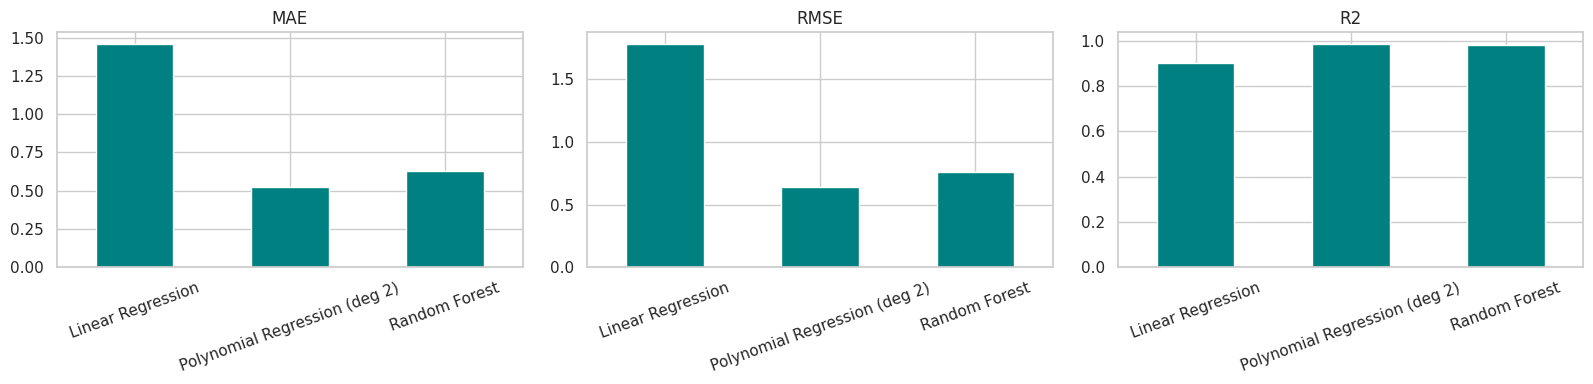

Best model by R2: Polynomial Regression (deg 2)


In [10]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, metric in zip(axes, ['MAE', 'RMSE', 'R2']):
    results[metric].plot(kind='bar', ax=ax, color='teal')
    ax.set_title(metric)
    ax.set_xlabel('')
    ax.tick_params(axis='x', rotation=20)
plt.tight_layout()
plt.show()

best_name = results['R2'].idxmax()
print('Best model by R2:', best_name)

## 7. Residual Plot for the Best Model
Residuals = actual - predicted. If the model is good, errors should scatter randomly around zero with no pattern.

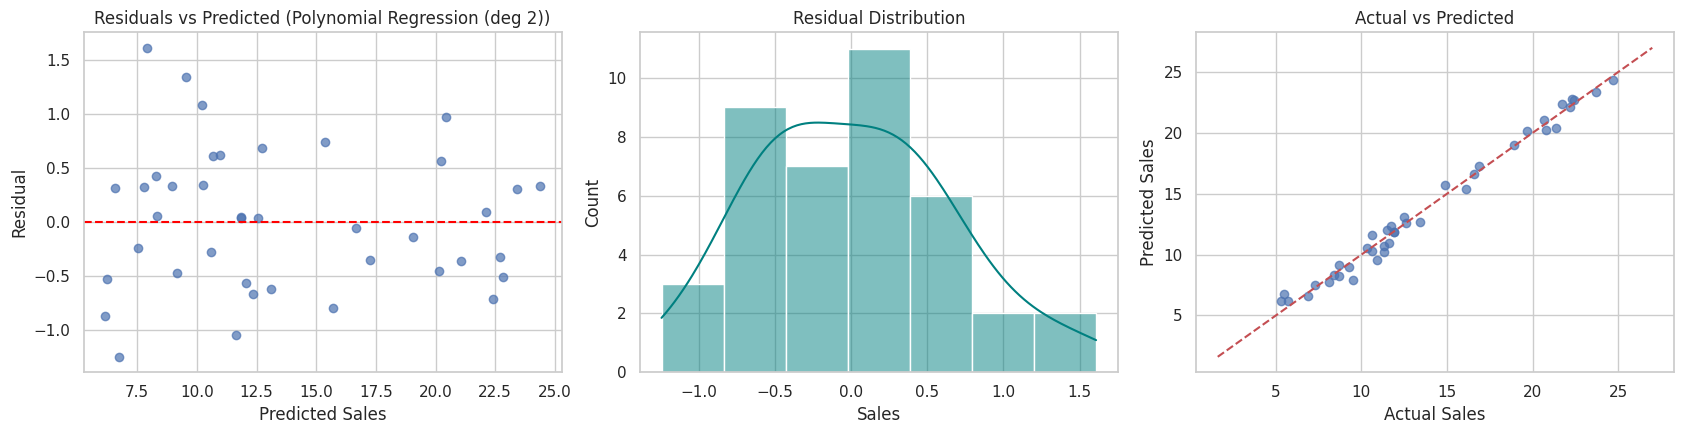

In [11]:
best_pred = preds[best_name]
residuals = y_test - best_pred

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))

axes[0].scatter(best_pred, residuals, alpha=0.7)
axes[0].axhline(0, color='red', linestyle='--')
axes[0].set_xlabel('Predicted Sales'); axes[0].set_ylabel('Residual')
axes[0].set_title(f'Residuals vs Predicted ({best_name})')

sns.histplot(residuals, kde=True, ax=axes[1], color='teal')
axes[1].set_title('Residual Distribution')

axes[2].scatter(y_test, best_pred, alpha=0.7)
lims = [y.min(), y.max()]
axes[2].plot(lims, lims, 'r--')
axes[2].set_xlabel('Actual Sales'); axes[2].set_ylabel('Predicted Sales')
axes[2].set_title('Actual vs Predicted')

plt.tight_layout()
plt.show()

**Observation on residuals:** The residuals are centred around zero (mean about 0.02) and show no strong trend against the predicted values. Their distribution is roughly bell-shaped. The largest error is about 1.6 sales units. This means the polynomial model's errors look random rather than systematic, which is a good sign. A slightly wider spread appears at lower predicted sales, but with only 40 test points this is not a strong pattern.

## 8. Which Channel Has the Highest Impact?

### 8.1 Linear Regression coefficients
We standardise the features first so the coefficients are directly comparable (otherwise they depend on each channel's spend scale).

Standardised coefficients (sales change per 1 std-dev increase in spend):
TV           3.764
Radio        2.792
Newspaper    0.056
dtype: float64

Raw coefficients (sales change per 1 unit of spend):
TV           0.0447
Radio        0.1892
Newspaper    0.0028
dtype: float64


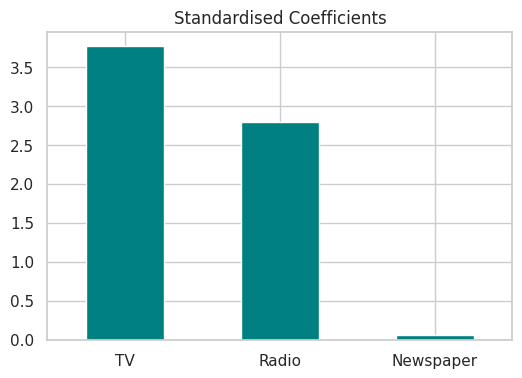

In [12]:
lr_std = make_pipeline(StandardScaler(), LinearRegression())
lr_std.fit(X_train, y_train)
coef = pd.Series(lr_std[-1].coef_, index=X.columns).sort_values(ascending=False)
print('Standardised coefficients (sales change per 1 std-dev increase in spend):')
print(coef.round(3))

# Raw coefficients: sales units per 1 unit of spend
raw = pd.Series(models['Linear Regression'].coef_, index=X.columns)
print('\nRaw coefficients (sales change per 1 unit of spend):')
print(raw.round(4))

coef.plot(kind='bar', color='teal', figsize=(6, 4))
plt.title('Standardised Coefficients'); plt.xticks(rotation=0)
plt.show()

### 8.2 Random Forest feature importance

TV           0.625
Radio        0.362
Newspaper    0.013
dtype: float64


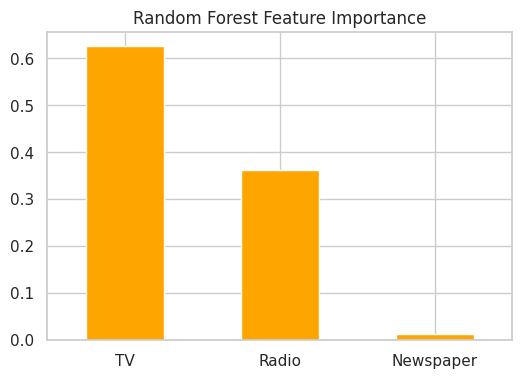

In [13]:
imp = pd.Series(models['Random Forest'].feature_importances_, index=X.columns).sort_values(ascending=False)
print(imp.round(3))
imp.plot(kind='bar', color='orange', figsize=(6, 4))
plt.title('Random Forest Feature Importance'); plt.xticks(rotation=0)
plt.show()

**Observation:** In the standardised coefficients, TV has the largest effect (3.76), then Radio (2.79), while Newspaper is almost zero (0.06). Random Forest agrees: TV (62.5%) > Radio (36.2%) > Newspaper (1.3%). In raw units, one extra unit of Radio spend is linked to a bigger sales increase (0.189) than one extra unit of TV spend (0.045), but TV budgets are much larger, so TV has the highest overall impact.

## 9. Conclusion

- **Best model:** Polynomial Regression (degree 2) with R² = 0.987, MAE = 0.53 and RMSE = 0.64 on the test set. Random Forest was close behind (R² = 0.982), and the Linear Regression baseline scored R² = 0.899.
- **Most impactful channel:** TV advertising, followed by Radio. Newspaper spend has almost no effect on sales (coefficient about 0.06 standardised, importance about 1%).
- **Business insight:** Money spent on newspaper ads brings little return. Budget is better moved to TV and Radio, and the two together work better than either alone.
- **Limitations:** The dataset has only 200 rows and a single train/test split, so results could shift slightly with different splits. The correlation seen here does not prove that advertising *causes* the sales.